# 向量趨勢：前三章 embedding 的年度變化（2016–2024）

三個問題，都在原始 1536 維算，不靠降維：
1. **供給**：每年所有書的平均向量有沒有移動？
2. **熱門**：每年前 10% 的平均向量有沒有移動？
3. **偏好**：每年「前 10% − 其他」的方向，不同年份像不像？相隔越久越不像嗎？

每個數字都和一個**雜訊下限**比：把同一年的書隨機分成兩半，兩半之間的差異就是「光靠抽樣就會有的差異」。
另外做一個「扣掉 tags 之後」的版本，看 embedding 有沒有看到 tags 以外的變化。

In [1]:
import json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")
OUT = Path("out"); FIG = OUT / "figs"; FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"font.sans-serif": ["PingFang TC", "Heiti TC", "Arial Unicode MS", "DejaVu Sans"], "axes.unicode_minus": False,
                     "figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
S = {}; rng = np.random.default_rng(0)
def save(name): plt.savefig(FIG / f"{name}.png", dpi=130, bbox_inches="tight"); plt.show()
t = pq.read_table(OUT / "books.parquet")
b = t.drop(["book_vec", "chap1_vec", "desc_vec"]).to_pandas()
vec = lambda c: t.column(c).combine_chunks().flatten().to_numpy().reshape(len(b), -1).astype(np.float32)
V, V1 = vec("book_vec"), vec("chap1_vec")
YEARS = list(range(2016, 2025)); yr = b.year.values; top = b.top10.values
unit = lambda x: x / np.linalg.norm(x)
cos = lambda a, c: float(np.dot(a, c) / np.linalg.norm(a) / np.linalg.norm(c))
print(V.shape, b.year.value_counts().sort_index().to_dict())

(45245, 1536) {2016: 2205, 2017: 2503, 2018: 2877, 2019: 2913, 2020: 4036, 2021: 4771, 2022: 5700, 2023: 8075, 2024: 12165}


## 1. 供給與熱門的平均位置：和 2016 的距離、和前一年的距離

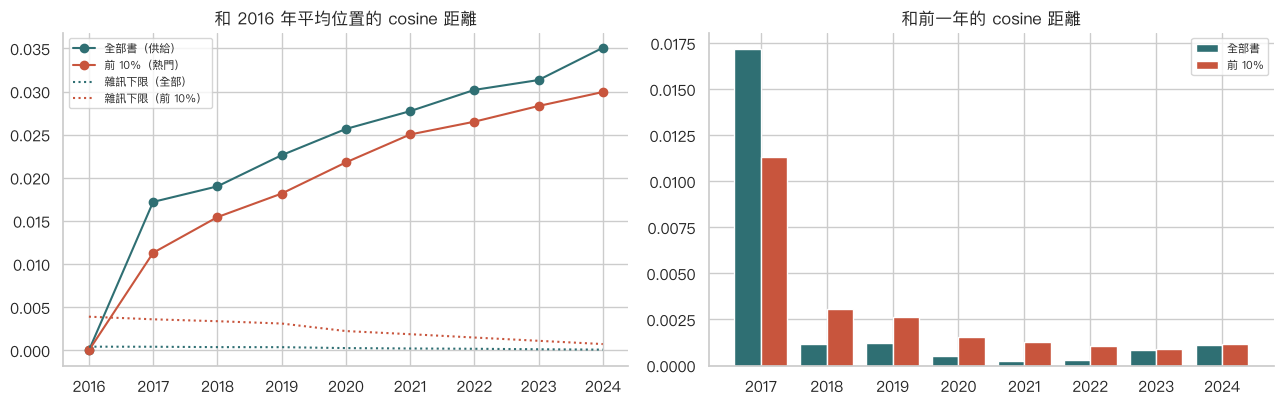

,供給：距 2016,供給雜訊,熱門：距 2016,熱門雜訊
2016,-0.0000,0.0004,0.0000,0.0039
2017,0.0172,0.0004,0.0113,0.0036
2018,0.0190,0.0004,0.0154,0.0034
2019,0.0226,0.0004,0.0182,0.0031
2020,0.0257,0.0003,0.0218,0.0022
2021,0.0277,0.0002,0.0250,0.0019
2022,0.0302,0.0002,0.0265,0.0015
2023,0.0313,0.0001,0.0283,0.0011
2024,0.0351,0.0001,0.0299,0.0007


In [2]:
def centroid_stats(M, mask_fn, B=200):
    cents = {y: unit(M[(yr == y) & mask_fn(y)].mean(0)) for y in YEARS}
    from_2016 = {y: 1 - cos(cents[2016], cents[y]) for y in YEARS}
    adj = {y: 1 - cos(cents[y - 1], cents[y]) for y in YEARS[1:]}
    noise = {}
    for y in YEARS:   # 同年隨機分兩半的距離 = 雜訊下限
        idx = np.flatnonzero((yr == y) & mask_fn(y)); ds_ = []
        for _ in range(B):
            p = rng.permutation(idx); h = len(p) // 2
            ds_.append(1 - cos(M[p[:h]].mean(0), M[p[h:]].mean(0)))
        noise[y] = float(np.mean(ds_))
    return cents, from_2016, adj, noise
allm = lambda y: np.ones(len(b), bool); topm = lambda y: top
c_all, f_all, a_all, n_all = centroid_stats(V, allm)
c_top, f_top, a_top, n_top = centroid_stats(V, topm)
S["supply_from_2016"] = f_all; S["supply_adjacent"] = a_all; S["supply_noise"] = n_all
S["hot_from_2016"] = f_top; S["hot_adjacent"] = a_top; S["hot_noise"] = n_top
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].plot(YEARS, list(f_all.values()), marker="o", color="#2f6f73", label="全部書（供給）")
ax[0].plot(YEARS, list(f_top.values()), marker="o", color="#c8553d", label="前 10%（熱門）")
ax[0].plot(YEARS, list(n_all.values()), ls=":", color="#2f6f73", label="雜訊下限（全部）")
ax[0].plot(YEARS, list(n_top.values()), ls=":", color="#c8553d", label="雜訊下限（前 10%）")
ax[0].set_title("和 2016 年平均位置的 cosine 距離"); ax[0].legend(fontsize=8)
ax[1].bar(np.array(YEARS[1:]) - .2, list(a_all.values()), width=.4, color="#2f6f73", label="全部書")
ax[1].bar(np.array(YEARS[1:]) + .2, list(a_top.values()), width=.4, color="#c8553d", label="前 10%")
ax[1].set_title("和前一年的 cosine 距離"); ax[1].legend(fontsize=8)
plt.tight_layout(); save("vec_centroid_drift")
pd.DataFrame({"供給：距 2016": f_all, "供給雜訊": n_all, "熱門：距 2016": f_top, "熱門雜訊": n_top}).round(4)

## 2. 偏好方向：每年「前 10% − 其他」，各年之間像不像？

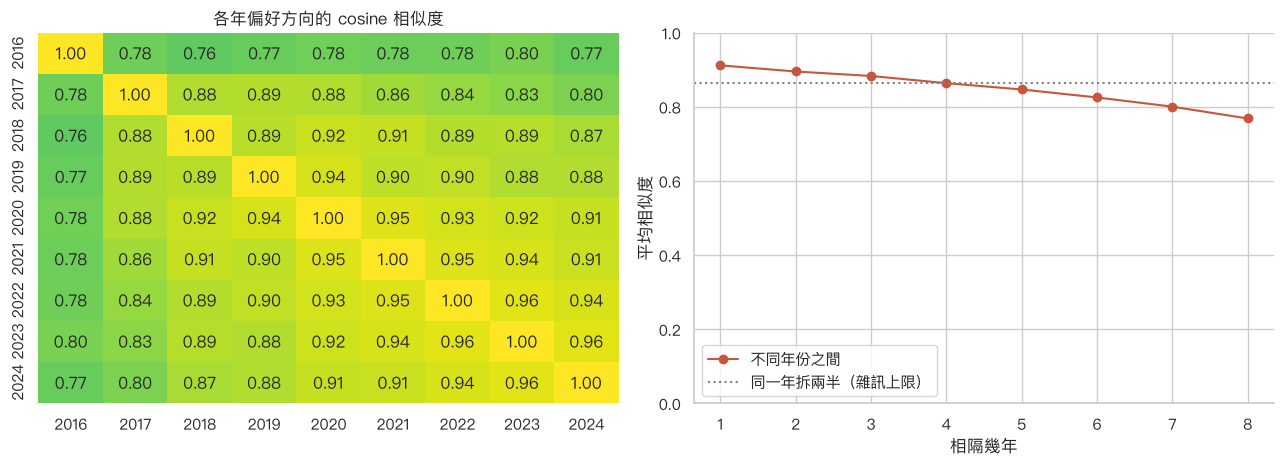

相隔年數 → 相似度 {1: 0.912, 2: 0.895, 3: 0.883, 4: 0.864, 5: 0.847, 6: 0.825, 7: 0.8, 8: 0.769}
同年拆兩半 {2016: 0.724, 2017: 0.775, 2018: 0.819, 2019: 0.839, 2020: 0.89, 2021: 0.918, 2022: 0.928, 2023: 0.94, 2024: 0.956}


In [3]:
def directions(M, idx_mask=None):
    return {y: M[(yr == y) & top].mean(0) - M[(yr == y) & ~top].mean(0) for y in YEARS}
def split_half_rel(M, B=100):
    rel = {}
    for y in YEARS:
        idx = np.flatnonzero(yr == y); vals = []
        for _ in range(B):
            p = rng.permutation(idx); h = len(p) // 2; a_, c_ = p[:h], p[h:]
            da = M[a_][top[a_]].mean(0) - M[a_][~top[a_]].mean(0); dc = M[c_][top[c_]].mean(0) - M[c_][~top[c_]].mean(0)
            vals.append(cos(da, dc))
        rel[y] = float(np.mean(vals))
    return rel
def dir_matrix(D):
    return pd.DataFrame([[cos(D[i], D[j]) for j in YEARS] for i in YEARS], index=YEARS, columns=YEARS)
D = directions(V); Dm = dir_matrix(D); rel = split_half_rel(V)
by_gap = {g: float(np.mean([Dm.loc[y, y + g] for y in YEARS if y + g in YEARS])) for g in range(1, 9)}
S["dir_corr"] = Dm.round(3).to_dict(); S["dir_by_gap"] = by_gap; S["dir_split_half"] = rel
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
sns.heatmap(Dm, ax=ax[0], cmap="viridis", annot=True, fmt=".2f", vmin=0, vmax=1, cbar=False); ax[0].set_title("各年偏好方向的 cosine 相似度")
ax[1].plot(list(by_gap), list(by_gap.values()), marker="o", color="#c8553d", label="不同年份之間")
ax[1].axhline(np.mean(list(rel.values())), ls=":", color="gray", label="同一年拆兩半（雜訊上限）")
ax[1].set_xlabel("相隔幾年"); ax[1].set_ylabel("平均相似度"); ax[1].set_ylim(0, 1); ax[1].legend()
plt.tight_layout(); save("vec_direction_stability")
print("相隔年數 → 相似度", {k: round(v, 3) for k, v in by_gap.items()}); print("同年拆兩半", {k: round(v, 3) for k, v in rel.items()})

## 3. 扣掉 tags 之後還剩多少？

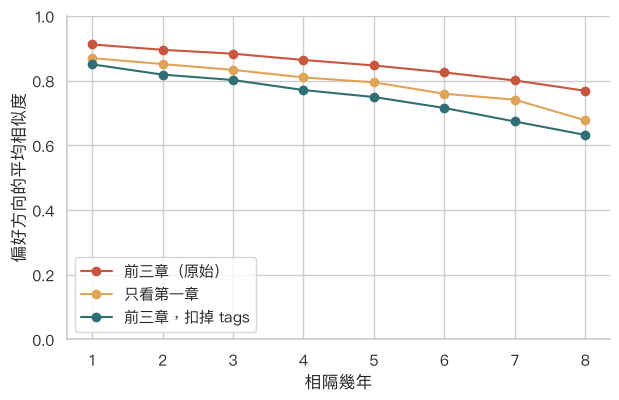

tags 能解釋向量變異的 10.3%
扣掉 tags： {1: 0.85, 2: 0.819, 3: 0.802, 4: 0.771, 5: 0.749, 6: 0.715, 7: 0.674, 8: 0.632}


In [4]:
tags = b.tags.map(lambda s: json.loads(s) if isinstance(s, str) and s else [])
vocab = sorted({x for l in tags for x in l})
T = np.zeros((len(b), len(vocab) + 1), np.float32); T[:, -1] = 1
pos = {v: i for i, v in enumerate(vocab)}
for r, l in enumerate(tags):
    for x in l: T[r, pos[x]] = 1
coef, *_ = np.linalg.lstsq(T, V, rcond=None)
R = V - T @ coef
S["tag_r2"] = float(1 - (R ** 2).sum() / ((V - V.mean(0)) ** 2).sum())
Dr = directions(R); Drm = dir_matrix(Dr); relr = split_half_rel(R)
by_gap_r = {g: float(np.mean([Drm.loc[y, y + g] for y in YEARS if y + g in YEARS])) for g in range(1, 9)}
S["dir_by_gap_resid"] = by_gap_r; S["dir_split_half_resid"] = relr
D1 = directions(V1); by_gap_1 = {g: float(np.mean([cos(D1[y], D1[y + g]) for y in YEARS if y + g in YEARS])) for g in range(1, 9)}
S["dir_by_gap_chap1"] = by_gap_1
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(list(by_gap), list(by_gap.values()), marker="o", color="#c8553d", label="前三章（原始）")
ax.plot(list(by_gap_1), list(by_gap_1.values()), marker="o", color="#e0a458", label="只看第一章")
ax.plot(list(by_gap_r), list(by_gap_r.values()), marker="o", color="#2f6f73", label="前三章，扣掉 tags")
ax.set_xlabel("相隔幾年"); ax.set_ylabel("偏好方向的平均相似度"); ax.set_ylim(0, 1); ax.legend()
save("vec_direction_variants")
print(f"tags 能解釋向量變異的 {S['tag_r2']:.1%}"); print("扣掉 tags：", {k: round(v, 3) for k, v in by_gap_r.items()})

## 3b. 校正雜訊：早期年份樣本少，方向本身比較不準

相隔 8 年的比較只有 2016 對 2024，而 2016 年的書最少、方向最不準（同年拆兩半的相似度只有 0.72）。
所以「相隔越久越不像」有一部分可能只是早期年份的雜訊。這裡用兩年各自的拆半可靠度校正：
校正後相似度 = 原始相似度 ÷ √(可靠度ᵢ × 可靠度ⱼ)。拆半可靠度是用一半樣本算的，所以先用 Spearman–Brown 換算成全樣本可靠度。

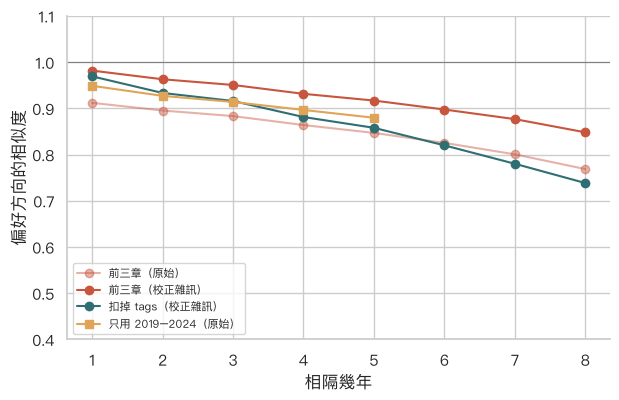

校正後 {1: 0.982, 2: 0.963, 3: 0.951, 4: 0.931, 5: 0.917, 6: 0.897, 7: 0.877, 8: 0.848}
扣 tags 校正後 {1: 0.969, 2: 0.933, 3: 0.916, 4: 0.881, 5: 0.858, 6: 0.82, 7: 0.78, 8: 0.738}
2019 以後 {1: 0.949, 2: 0.927, 3: 0.914, 4: 0.896, 5: 0.88}


In [5]:
def disatt(M, rel_half):
    full = {y: 2 * r / (1 + r) for y, r in rel_half.items()}           # Spearman–Brown
    return {g: float(np.mean([M.loc[y, y + g] / np.sqrt(full[y] * full[y + g]) for y in YEARS if y + g in YEARS])) for g in range(1, 9)}, full
adj_raw, full_rel = disatt(Dm, rel); adj_res, _ = disatt(Drm, relr)
S["dir_by_gap_disatt"] = adj_raw; S["dir_by_gap_resid_disatt"] = adj_res; S["dir_full_reliability"] = full_rel
# 只用 2019 以後（每年樣本較多）再看一次
Y19 = [y for y in YEARS if y >= 2019]
late = {g: float(np.mean([Dm.loc[y, y + g] for y in Y19 if y + g in Y19])) for g in range(1, 6)}
S["dir_by_gap_2019on"] = late
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(list(by_gap), list(by_gap.values()), marker="o", color="#c8553d", alpha=.45, label="前三章（原始）")
ax.plot(list(adj_raw), list(adj_raw.values()), marker="o", color="#c8553d", label="前三章（校正雜訊）")
ax.plot(list(adj_res), list(adj_res.values()), marker="o", color="#2f6f73", label="扣掉 tags（校正雜訊）")
ax.plot(list(late), list(late.values()), marker="s", color="#e0a458", label="只用 2019–2024（原始）")
ax.axhline(1, color="gray", lw=.8); ax.set_xlabel("相隔幾年"); ax.set_ylabel("偏好方向的相似度"); ax.set_ylim(.4, 1.1); ax.legend(fontsize=8)
save("vec_direction_disatt")
print("校正後", {k: round(v, 3) for k, v in adj_raw.items()}); print("扣 tags 校正後", {k: round(v, 3) for k, v in adj_res.items()}); print("2019 以後", {k: round(v, 3) for k, v in late.items()})

## 4. PCA 平面上的軌跡（解釋用）

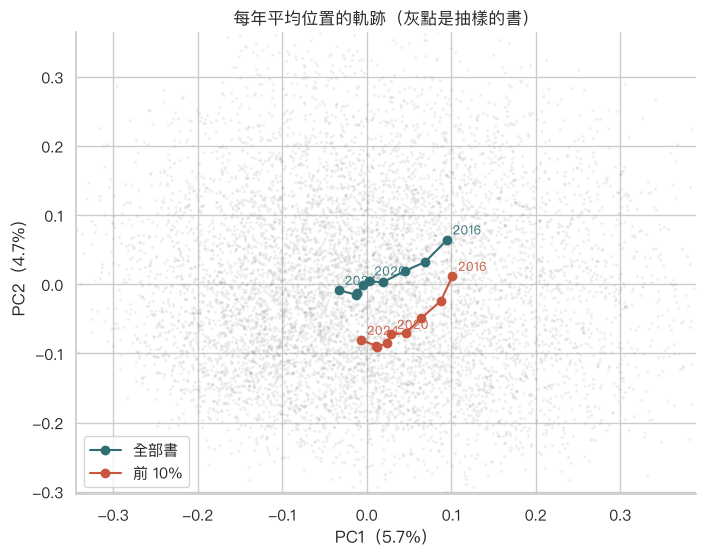

In [6]:
ev = json.load(open(OUT / "projection_summary.json"))["pca_explained"]
traj = pd.DataFrame({"x_all": b.groupby("year").pca_x.mean(), "y_all": b.groupby("year").pca_y.mean(),
                     "x_top": b[b.top10].groupby("year").pca_x.mean(), "y_top": b[b.top10].groupby("year").pca_y.mean()}).loc[YEARS]
S["pca_traj"] = traj.round(4).to_dict("index"); S["pca_explained"] = ev
fig, ax = plt.subplots(figsize=(8, 6))
smp = b.sample(min(8000, len(b)), random_state=0)
ax.scatter(smp.pca_x, smp.pca_y, s=2, alpha=.08, color="gray")
for cx, cy, colr, lab in (("x_all", "y_all", "#2f6f73", "全部書"), ("x_top", "y_top", "#c8553d", "前 10%")):
    ax.plot(traj[cx], traj[cy], marker="o", color=colr, label=lab)
    for y in (2016, 2020, 2024): ax.annotate(str(y), (traj.loc[y, cx], traj.loc[y, cy]), fontsize=9, color=colr, xytext=(4, 4), textcoords="offset points")
lo, hi = smp[["pca_x","pca_y"]].quantile(.02), smp[["pca_x","pca_y"]].quantile(.98)
pad = .15 * (hi - lo); ax.set_xlim(lo.pca_x - pad.pca_x, hi.pca_x + pad.pca_x); ax.set_ylim(lo.pca_y - pad.pca_y, hi.pca_y + pad.pca_y)
ax.set_xlabel(f"PC1（{ev[0]:.1%}）"); ax.set_ylabel(f"PC2（{ev[1]:.1%}）"); ax.legend(); ax.set_title("每年平均位置的軌跡（灰點是抽樣的書）")
save("vec_pca_trajectory")

In [7]:
# PC1、PC2 兩端分別是什麼樣的書：比較最高與最低 10% 的 tag 占比
def axis_tags(col):
    q_lo, q_hi = b[col].quantile([.1, .9]); lo_, hi_ = b[b[col] <= q_lo], b[b[col] >= q_hi]
    share = lambda d: d.tags.map(lambda s: json.loads(s) if isinstance(s, str) and s else []).explode().value_counts() / len(d)
    diff = (share(hi_) - share(lo_)).dropna().sort_values()
    return {"高的一端": diff.tail(6).iloc[::-1].round(3).to_dict(), "低的一端": diff.head(6).round(3).to_dict()}
S["axis_tags"] = {"PC1": axis_tags("pca_x"), "PC2": axis_tags("pca_y")}
S["axis_tags"]

{'PC1': {'高的一端': {'LitRPG': 0.49,
   'Adventure': 0.328,
   'Action': 0.306,
   'Reincarnation': 0.286,
   'Fantasy': 0.26,
   'Martial Arts': 0.185},
  '低的一端': {'Female Lead': -0.428,
   'Drama': -0.294,
   'Multiple Lead Characters': -0.272,
   'Romance': -0.231,
   'Urban Fantasy': -0.139,
   'Low Fantasy': -0.127}},
 'PC2': {'高的一端': {'Romance': 0.389,
   'School Life': 0.219,
   'Martial Arts': 0.194,
   'Drama': 0.153,
   'Reincarnation': 0.142,
   'Slice of Life': 0.135},
  '低的一端': {'LitRPG': -0.363,
   'Sci-fi': -0.296,
   'Adventure': -0.223,
   'GameLit': -0.222,
   'Magic': -0.214,
   'Progression': -0.196}}}

In [8]:
def clean(o):
    if isinstance(o, dict): return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [clean(v) for v in o]
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating, float)): return None if np.isnan(o) else float(o)
    return o
(OUT / "drift_summary.json").write_text(json.dumps(clean(S), ensure_ascii=False, indent=1)); print("saved")

saved
